# Transient stability prediction for the IEEE 39-bus system with a Random Forest


| | |
|---|---|
| **Inputs (80)** | for each of the 10 generators: 4 voltage-magnitude samples (p.u.) + 4 frequency samples (Hz) |
| **Label** | `Overall_Stability` from the TSI value: **1 = stable, 0 = unstable** |
| **Contingencies** | generator trip, line trip, ground fault + line trip (SLG / LLG / 3PHG), load disconnection |
| **Scenarios** | each contingency simulated at 5 load levels (-4 %, -2 %, 0 %, +2 %, +4 %) and, for faults, 3 fault durations |
| **Model** | Random forest (scikit-learn) |

**Why a random forest?** It is a vote of many decision trees, each grown on a bootstrap sample of the cases and trying
a random subset of the inputs at every split. Trees split on thresholds, so the inputs need **no scaling** and extreme
values cannot distort the model through distances. The forest also reports which inputs it uses.

**First try:** all 3,715 cases are used and **no outliers are removed**.

**Workflow:** load → explore → split into train / validation / test → choose forest settings → check on validation →
final test → feature importance → save model and predict new cases.



In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from rf_stability import data, model, evaluate, plots
from rf_stability.config import FEATURES, LABEL, GROUP, STABLE, UNSTABLE, BUSES, MODEL_FILE

plots.apply_style()
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)

def show(fig, name):
    """Display a figure and keep a PNG copy in figures/."""
    plots.save(fig, name)
    plt.show()

## 1. Load the data

In [3]:
raw = data.load_dataset()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns  ({len(FEATURES)} measurement columns)")
display(raw.head())
display(data.quality_report(raw).to_frame())

3,715 rows x 85 columns  (80 measurement columns)


,Case_ID,Operating_Condition,Contingency_Type,Contingency_ID,B30_Vmag_1,B30_Vmag_2,B30_Vmag_3,B30_Vmag_4,B31_Vmag_1,B31_Vmag_2,B31_Vmag_3,B31_Vmag_4,B32_Vmag_1,B32_Vmag_2,B32_Vmag_3,...,B36_FreqHz_3,B36_FreqHz_4,B37_FreqHz_1,B37_FreqHz_2,B37_FreqHz_3,B37_FreqHz_4,B38_FreqHz_1,B38_FreqHz_2,B38_FreqHz_3,B38_FreqHz_4,B39_FreqHz_1,B39_FreqHz_2,B39_FreqHz_3,B39_FreqHz_4,Overall_Stability
0,GT_00001,-4%,Generator_Trip,GenTrip_Bus30,0.9538,0.9532,0.9528,0.9524,0.8109,0.8102,0.8097,0.8093,0.9810,0.9802,0.9796,...,49.9997,49.9978,49.9942,49.9829,49.9770,49.9728,49.9991,49.9970,49.9955,49.9940,49.9994,49.9983,49.9978,49.9974,1
1,GT_00002,-4%,Generator_Trip,GenTrip_Bus31,1.0003,0.9978,0.9961,0.9948,0.6737,0.6710,0.6690,0.6674,0.9668,0.9614,0.9572,...,50.0024,49.9976,49.9985,49.9940,49.9897,49.9852,49.9994,49.9979,49.9968,49.9955,49.9987,49.9963,49.9951,49.9941,1
2,GT_00003,-4%,Generator_Trip,GenTrip_Bus32,0.9982,0.9951,0.9930,0.9916,0.7619,0.7581,0.7555,0.7537,0.8081,0.8050,0.8027,...,49.9988,49.9920,49.9972,49.9899,49.9836,49.9774,49.9990,49.9965,49.9946,49.9926,49.9985,49.9956,49.9942,49.9932,1
3,GT_00004,-4%,Generator_Trip,GenTrip_Bus33,1.0037,1.0020,1.0007,0.9998,0.8082,0.8063,0.8048,0.8036,0.9805,0.9790,0.9777,...,49.9746,49.9665,49.9967,49.9887,49.9829,49.9771,49.9988,49.9952,49.9923,49.9893,49.9997,49.9987,49.9980,49.9973,1
4,GT_00005,-4%,Generator_Trip,GenTrip_Bus34,1.0054,1.0047,1.0042,1.0037,0.8124,0.8118,0.8110,0.8102,0.9817,0.9813,0.9808,...,49.9827,49.9783,49.9984,49.9938,49.9903,49.9867,49.9994,49.9975,49.9958,49.9941,49.9998,49.9993,49.9989,49.9985,1


,count
rows,3715
columns,85
missing values,0
infinite values,0
duplicate rows,0
rows with voltage > 1.1 p.u.,10
rows with |f - 50| > 5 Hz,10
rows with an impossible reading,10


No missing values or duplicates. **10 rows contain physically impossible readings** (voltages up to 13 p.u.,
frequencies between 24 and 81 Hz). For this first try they are **kept**.

Readable scenario columns are parsed from `Contingency_ID` (fault kind, fault duration) and `Operating_Condition`
(load change). They are used only for analysis - the forest sees just the 80 measurements.

In [4]:
df = data.add_scenario_details(raw)
display(df[["Case_ID", "Operating_Condition", "Contingency_Type", "Contingency_ID",
            "Fault_Kind", "Fault_Time_s", "Load_Change_pct", LABEL]].sample(6, random_state=1))
print(f"{df[GROUP].nunique()} distinct contingencies, each at {df.groupby(GROUP).size().unique()} load levels")

,Case_ID,Operating_Condition,Contingency_Type,Contingency_ID,Fault_Kind,Fault_Time_s,Load_Change_pct,Overall_Stability
3547,GF_03548,+4%,Ground_Fault_Line_Trip,SLG_Line17_18_Ckt1_Loc20pct_Fault0p5s,SLG,0.5,4.0,1
3017,GF_03018,+2%,Ground_Fault_Line_Trip,3PHG_Line25_26_Ckt1_Loc20pct_Fault0p1s,3PHG,0.1,2.0,1
3304,GF_03305,+4%,Ground_Fault_Line_Trip,LLG_Line6_11_Ckt1_Loc80pct_Fault0p1s,LLG,0.1,4.0,1
1773,GF_01774,-2%,Ground_Fault_Line_Trip,LLG_Line23_24_Ckt1_Loc20pct_Fault0p1s,LLG,0.1,-2.0,1
1794,GF_01795,-2%,Ground_Fault_Line_Trip,3PHG_Line25_26_Ckt1_Loc80pct_Fault0p1s,3PHG,0.1,-2.0,1
99,LD_00100,0%,Load_Disconnection,LoadDisconnect_Bus24_ID1,Load disconnection,NaN,0.0,1


743 distinct contingencies, each at [5] load levels


## 2. Explore the data

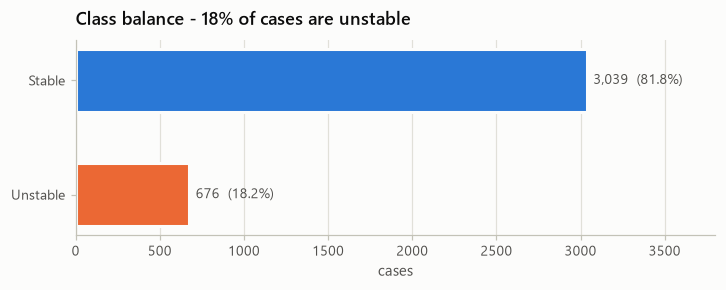

In [5]:
show(plots.plot_class_balance(df), "01_class_balance")

Only about 1 case in 5 is unstable, so a model that always says "stable" would already be 81.8 % accurate. The forest
therefore uses **class weights**, and results are reported as **balanced accuracy** (average of the stable and
unstable hit rates) and **unstable recall** (share of unstable cases caught).

,cases,unstable,unstable_%
Contingency_Type,,,
Generator_Trip,50,5,10.0
Ground_Fault_Line_Trip,3060,458,15.0
Line_Trip,510,213,41.8
Load_Disconnection,95,0,0.0


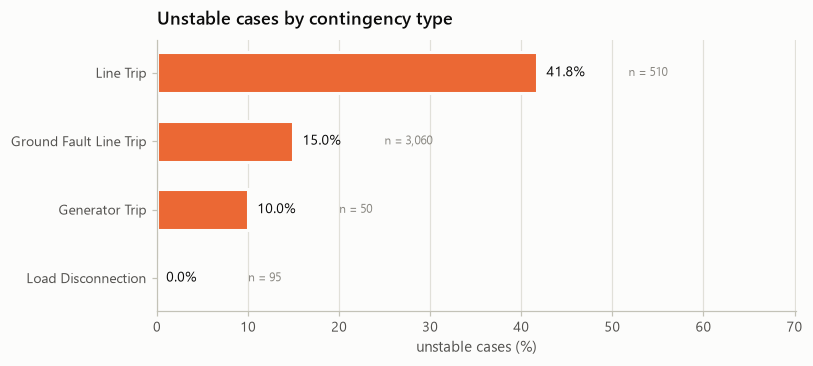

In [6]:
tab = df.groupby("Contingency_Type")[LABEL].agg(cases="size", unstable=lambda s: int((s == UNSTABLE).sum()))
tab["unstable_%"] = (100 * tab["unstable"] / tab["cases"]).round(1)
display(tab)
show(plots.plot_unstable_rate(df, "Contingency_Type", title="Unstable cases by contingency type"),
     "02_unstable_by_contingency_type")

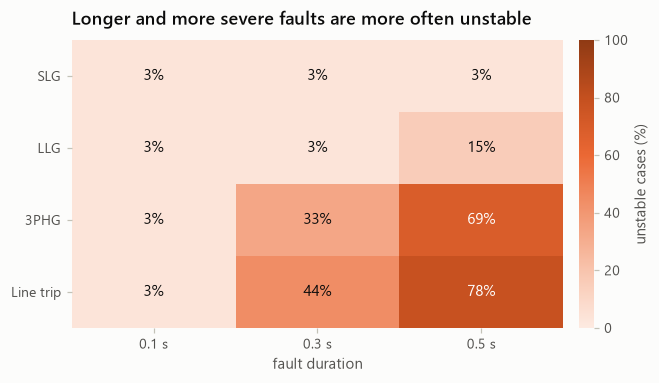

In [7]:
show(plots.plot_fault_time_heatmap(df), "03_unstable_by_fault_and_time")

* **Fault duration** is the strongest driver: with 0.1 s clearing almost every fault is stable; at 0.5 s many are not.
* **Fault type:** three-phase-to-ground (3PHG) faults are far more severe than LLG, which are more severe than SLG.
* The few unstable 0.1 s cases are all on **line 16-19** - tripping it separates buses 19, 20, 33 and 34 (the
  generators at B33 and B34) from the rest of the network, so every contingency on that line is unstable.

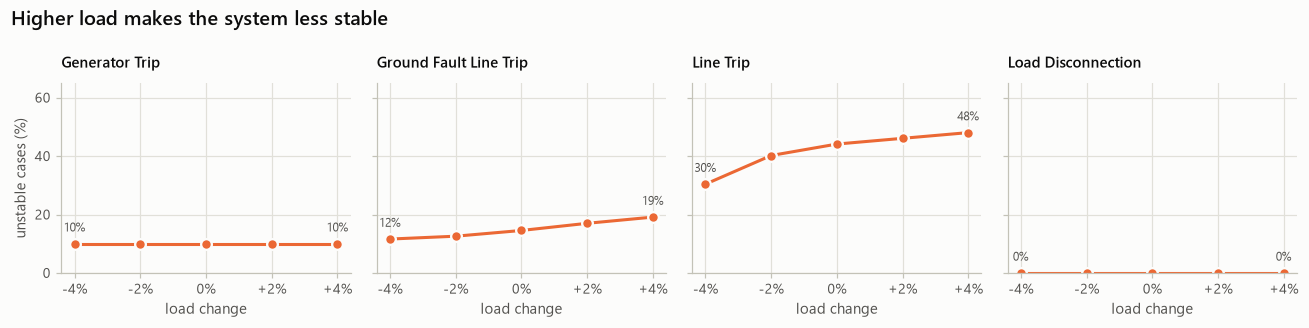

In [8]:
show(plots.plot_rate_vs_load(df), "04_unstable_vs_load")

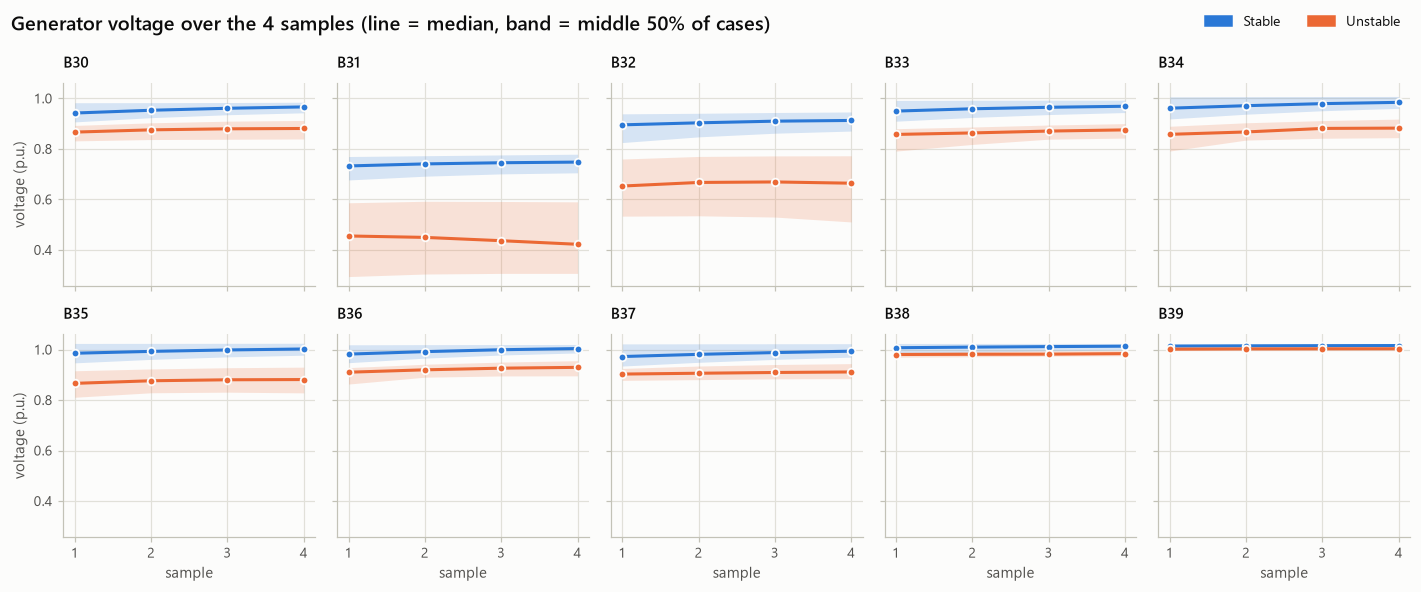

In [9]:
show(plots.plot_sample_traces(df, "voltage"), "05_voltage_traces")

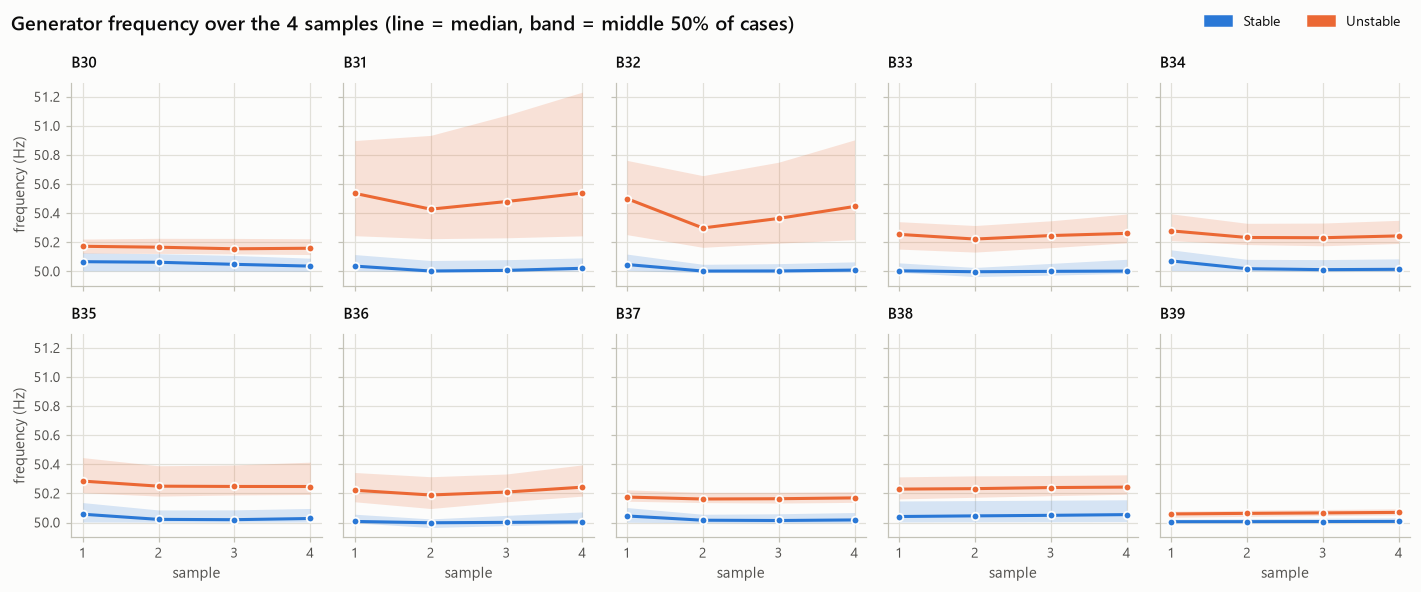

In [10]:
show(plots.plot_sample_traces(df, "frequency"), "06_frequency_traces")

Unstable cases show clearly **lower generator voltages** (largest gaps at B31 and B32) and **higher, more spread-out
frequencies**. B39 differs least between the classes.

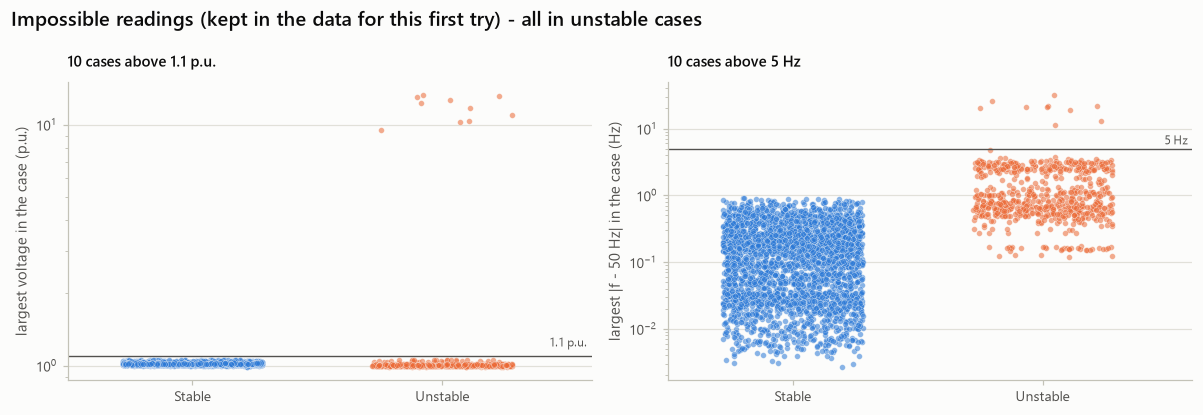

,Case_ID,Operating_Condition,Contingency_ID,Overall_Stability
1044,GF_01045,-4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
1050,GF_01051,-4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
1656,GF_01657,-2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
1662,GF_01663,-2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
2268,GF_02269,0%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
2274,GF_02275,0%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
2880,GF_02881,+2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
2886,GF_02887,+2%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0
3492,GF_03493,+4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p3s,0
3498,GF_03499,+4%,3PHG_Line16_19_Ckt1_Loc80pct_Fault0p5s,0


In [11]:
show(plots.plot_extreme_values(df), "07_impossible_readings")
display(df[data.extreme_rows(df)][["Case_ID", "Operating_Condition", "Contingency_ID", LABEL]])

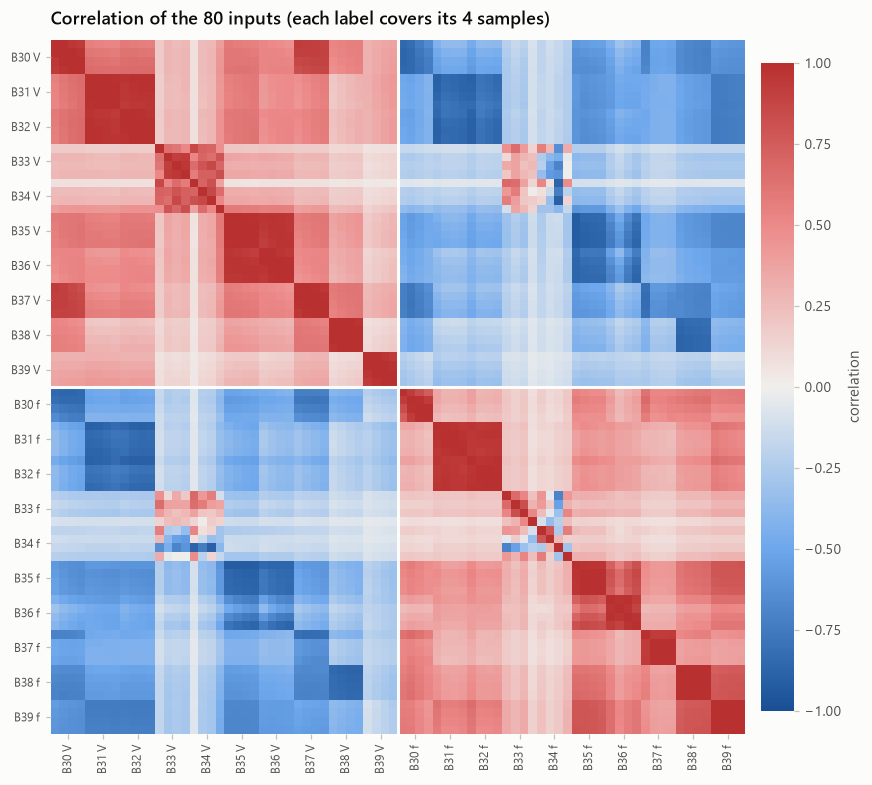

In [12]:
show(plots.plot_correlation(df), "08_correlation")

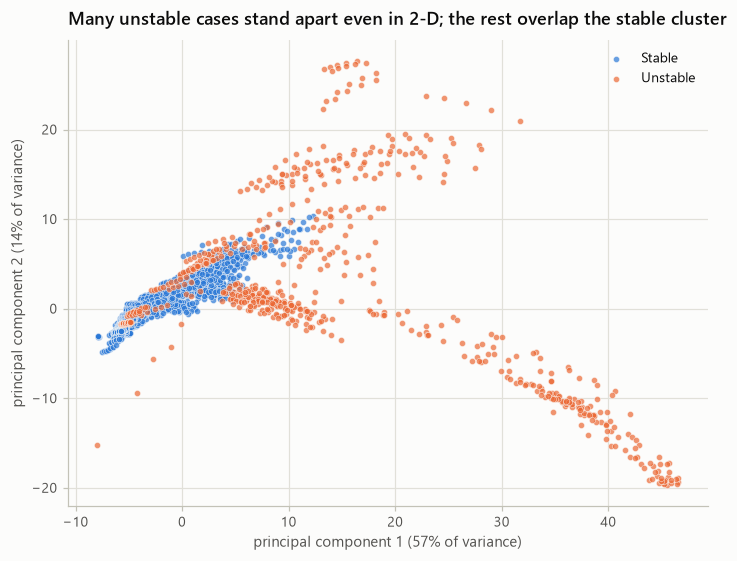

In [13]:
show(plots.plot_pca(df), "09_pca")

The 4 samples of each bus are strongly correlated, and a 2-D projection already separates many unstable cases while
the rest overlap the stable cluster - a non-linear model using all 80 inputs is needed.

## 3. Split into train / validation / test

The split is made **by contingency**: all 5 load levels of one contingency go into the same set, so the test score
describes contingencies the forest has never seen. Each set keeps about the same share of unstable cases. The 2
contingencies with impossible readings are placed in the **training** set, so this first try trains *with* them.

,rows,contingencies,stable,unstable,unstable_pct,share_of_rows_pct
set,,,,,,
Train,2655,531,2172,483,18.2,71.5
Validation,530,106,434,96,18.1,14.3
Test,530,106,433,97,18.3,14.3


contingencies shared by train and validation: 0
contingencies shared by train and test: 0
contingencies shared by validation and test: 0
rows with impossible readings (train / validation / test): [10, 0, 0]


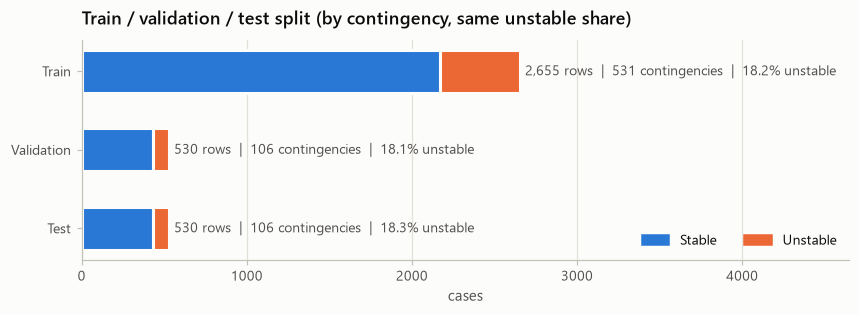

In [14]:
train, val, test = data.split_train_val_test(df)
summary = data.split_summary(train, val, test)
display(summary)
for a, b, n1, n2 in ((train, val, "train", "validation"), (train, test, "train", "test"), (val, test, "validation", "test")):
    print(f"contingencies shared by {n1} and {n2}: {len(set(a[GROUP]) & set(b[GROUP]))}")
print("rows with impossible readings (train / validation / test):",
      [int(data.extreme_rows(s).sum()) for s in (train, val, test)])
show(plots.plot_split_composition(summary), "10_split")

## 4. Choose the forest settings

* **max_depth** - how deep each tree may grow (no limit, 16 or 8 levels)
* **min_samples_leaf** - smallest number of training cases in a leaf (larger = smoother trees)
* **max_features** - share of the 80 inputs tried at each split (`sqrt` ≈ 9 inputs, 0.3 = 24, 0.6 = 48)
* **class_weight** - `balanced` (weights from the whole training set) or `balanced_subsample` (per bootstrap sample)

Each forest has 300 trees. Every combination is scored by **grouped 5-fold cross-validation inside the training set**:
the training contingencies are split into 5 groups, each held out once, and the 5 balanced accuracies are averaged.

,max_depth,min_samples_leaf,max_features,class_weight,cv_bal_acc,cv_std
0,None,10,0.3,balanced,0.9417,0.0405
1,16,10,0.3,balanced,0.9417,0.0405
2,8,10,0.3,balanced,0.9417,0.0405
3,None,3,0.6,balanced,0.9412,0.0388
4,16,3,0.6,balanced,0.9412,0.0388
5,8,3,0.6,balanced,0.9412,0.0388
6,None,1,0.6,balanced,0.9407,0.0392
7,16,1,0.6,balanced,0.9407,0.0392
8,None,10,0.6,balanced,0.9399,0.0368
9,16,10,0.6,balanced,0.9399,0.0368


Chosen settings: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 10}


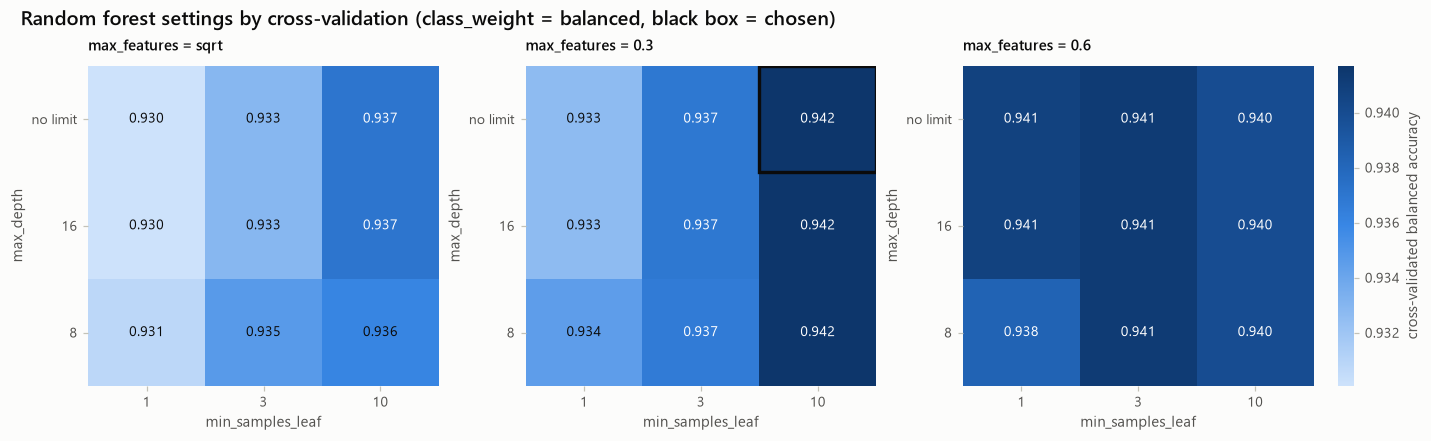

In [15]:
X_tr, y_tr = data.get_xy(train)
cv_results, best = model.tune_rf_with_cv(X_tr, y_tr, train[GROUP])
display(cv_results.head(10))
print("Chosen settings:", best)
show(plots.plot_rf_grid(cv_results, best), "11_cv_grid")

Identical scores for different `max_depth` values mean the depth limit is never reached with these leaf sizes - the
trees stop growing earlier on their own.

## 5. Check the chosen forest on the validation set

In [16]:
selection_model = model.build_rf(**best, n_jobs=-1).fit(X_tr, y_tr)
_, _, m_train = evaluate.evaluate(selection_model, train)
val_pred, val_prob, m_val = evaluate.evaluate(selection_model, val)
display(pd.DataFrame({"Train": m_train, "Validation": m_val}).T)
display(evaluate.confusion(val[LABEL], val_pred))
display(evaluate.errors_by_contingency(val, val_pred, val_prob))

,accuracy,balanced_accuracy,unstable_recall,unstable_precision,unstable_f1,stable_recall,roc_auc,average_precision
Train,0.9834,0.9891,0.9979,0.9181,0.9563,0.9802,0.9996,0.9983
Validation,0.9698,0.9694,0.9688,0.8774,0.9208,0.9700,0.9968,0.9866


,predicted Unstable,predicted Stable
actual Unstable,93,3
actual Stable,13,421


,cases,load_levels,p_min,p_max,error
Contingency_ID,,,,,
LineTrip_2_3_Ckt1_Fault0p5s,2,"-4%, -2%",0.376,0.389,missed unstable
LineTrip_2_25_Ckt1_Fault0p5s,1,-4%,0.488,0.488,missed unstable
3PHG_Line16_17_Ckt1_Loc20pct_Fault0p3s,3,"-4%, -2%, 0%",0.738,0.850,false alarm
3PHG_Line16_24_Ckt1_Loc80pct_Fault0p3s,3,"0%, +2%, +4%",0.530,0.539,false alarm
3PHG_Line9_39_Ckt1_Loc80pct_Fault0p5s,3,"-2%, 0%, +2%",0.516,0.556,false alarm
3PHG_Line17_18_Ckt1_Loc80pct_Fault0p5s,1,+2%,0.730,0.730,false alarm
LLG_Line5_8_Ckt1_Loc80pct_Fault0p5s,1,+4%,0.634,0.634,false alarm
LineTrip_3_4_Ckt1_Fault0p5s,1,-4%,0.702,0.702,false alarm
LineTrip_4_14_Ckt1_Fault0p3s,1,-2%,0.636,0.636,false alarm


,fraction,training_rows,train_bal_acc,val_bal_acc
0,0.1,265,0.9879,0.8809
1,0.2,530,0.9871,0.8809
2,0.4,1060,0.9872,0.8803
3,0.6,1595,0.9865,0.9526
4,0.8,2125,0.9898,0.9711
5,1.0,2655,0.9891,0.9694


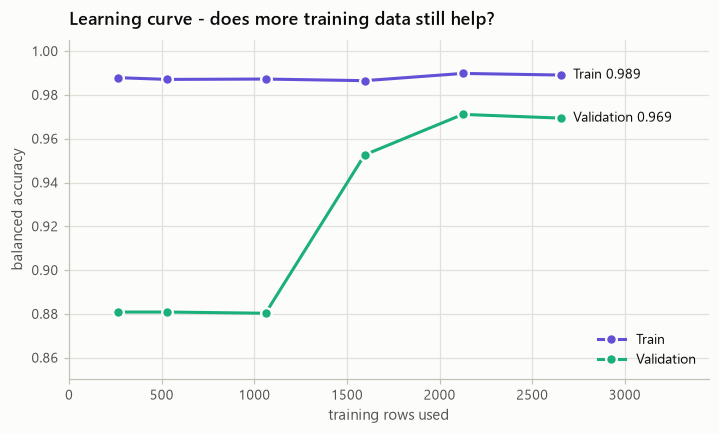

In [17]:
lc = evaluate.learning_curve_on_validation(train, val, best)
display(lc)
show(plots.plot_learning_curve(lc), "12_learning_curve")

## 6. Final forest and test set

The chosen settings are refitted on **train + validation**, and the final forest is evaluated **once** on the untouched
test set. Its output is the **predicted probability of instability**; above 0.5 → unstable.

Cross-validation on train: balanced accuracy 0.9417 +/- 0.0405
Train / Validation rows: forest fitted on train.  Test row: final forest (train + validation).


,accuracy,balanced_accuracy,unstable_recall,unstable_precision,unstable_f1,stable_recall,roc_auc,average_precision
Train,0.9834,0.9891,0.9979,0.9181,0.9563,0.9802,0.9996,0.9983
Validation,0.9698,0.9694,0.9688,0.8774,0.9208,0.9700,0.9968,0.9866
Test,0.9528,0.9551,0.9588,0.8158,0.8815,0.9515,0.9931,0.9739


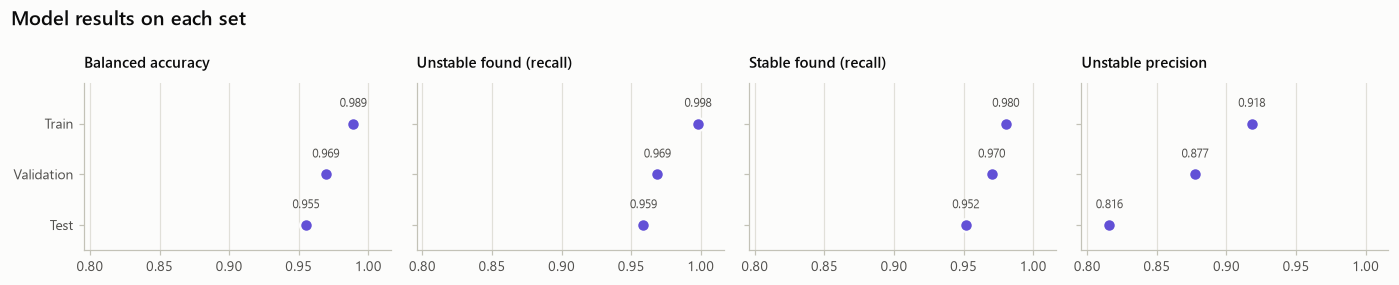

In [18]:
trainval = pd.concat([train, val])
final = model.build_rf(**best, n_jobs=-1).fit(*data.get_xy(trainval))
test_pred, test_prob, m_test = evaluate.evaluate(final, test)

m_cv = {"balanced_accuracy": float(cv_results.iloc[0]["cv_bal_acc"]), "std": float(cv_results.iloc[0]["cv_std"])}
results = pd.DataFrame({"Train": m_train, "Validation": m_val, "Test": m_test}).T
print(f"Cross-validation on train: balanced accuracy {m_cv['balanced_accuracy']:.4f} +/- {m_cv['std']:.4f}")
print("Train / Validation rows: forest fitted on train.  Test row: final forest (train + validation).")
display(results)
show(plots.plot_metric_dots(results), "13_metrics_by_set")

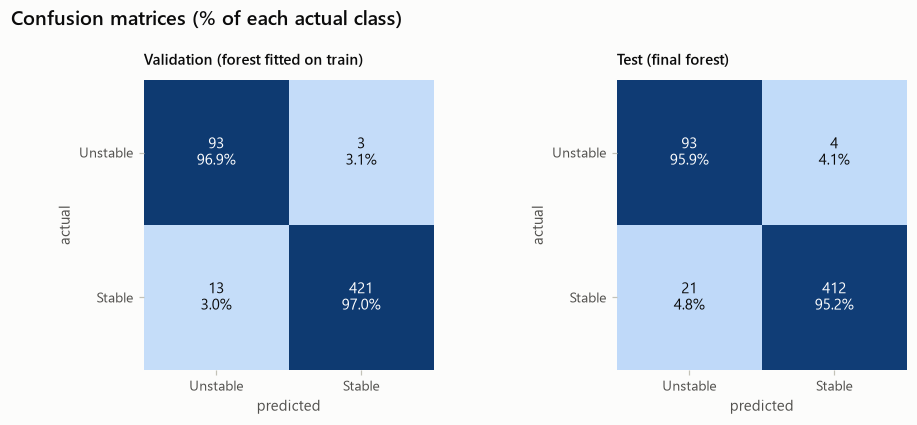

In [19]:
show(plots.plot_confusion_matrices({
    "Validation (forest fitted on train)": evaluate.confusion(val[LABEL], val_pred),
    "Test (final forest)": evaluate.confusion(test[LABEL], test_pred)}), "14_confusion_matrices")

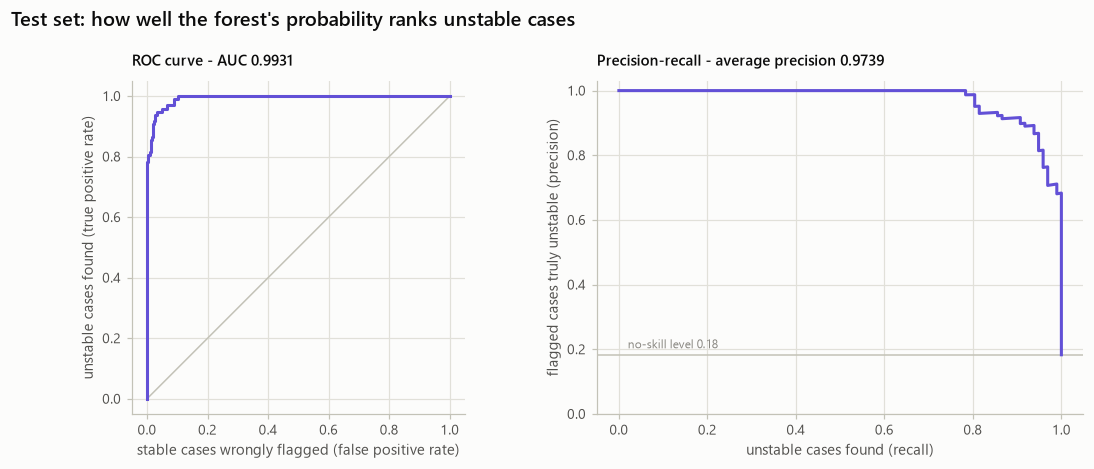

In [20]:
show(plots.plot_roc_pr(test[LABEL], test_prob), "15_roc_pr_test")

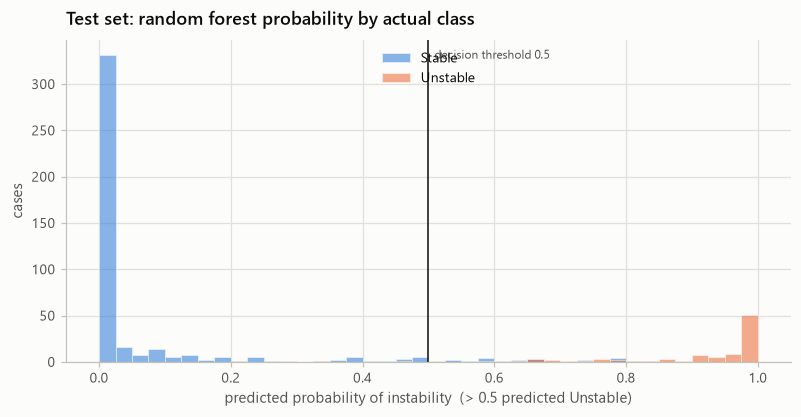

In [21]:
show(plots.plot_probability_distribution(test[LABEL], test_prob), "16_probability_distribution_test")

,cases,accuracy,unstable,unstable_found,unstable_missed,false_alarms
Contingency_Type,,,,,,
Generator_Trip,5,1.0000,0,0,0,0
Ground_Fault_Line_Trip,435,0.9632,64,60,4,12
Line_Trip,80,0.8875,33,33,0,9
Load_Disconnection,10,1.0000,0,0,0,0


,cases,accuracy,unstable,unstable_found,unstable_missed,false_alarms
Load_Change_pct,,,,,,
-4.0,106,0.9245,14,12,2,6
-2.0,106,0.9434,17,16,1,5
0.0,106,0.9717,21,20,1,2
2.0,106,0.9623,22,22,0,4
4.0,106,0.9623,23,23,0,4


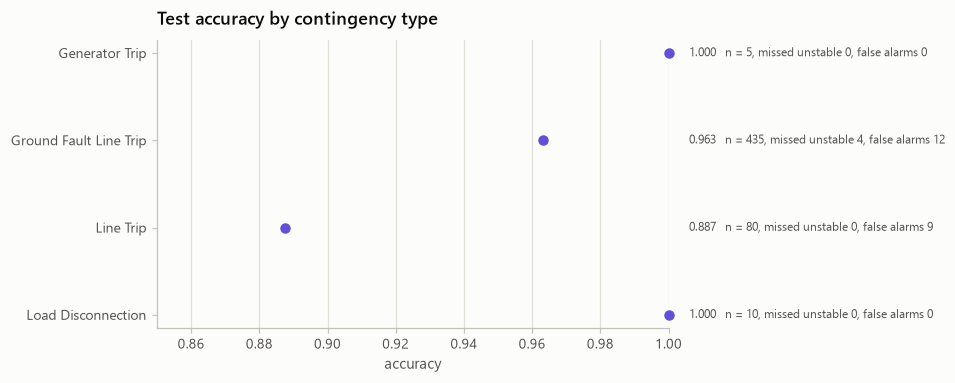

In [22]:
by_type = evaluate.breakdown(test, test_pred, "Contingency_Type")
display(by_type)
display(evaluate.breakdown(test, test_pred, "Load_Change_pct"))
show(plots.plot_breakdown_dots(by_type, "Test accuracy by contingency type"), "17_test_by_contingency_type")

In [23]:
display(evaluate.errors_by_contingency(test, test_pred, test_prob))

,cases,load_levels,p_min,p_max,error
Contingency_ID,,,,,
3PHG_Line28_29_Ckt1_Loc80pct_Fault0p5s,3,"-4%, -2%, 0%",0.212,0.460,missed unstable
3PHG_Line28_29_Ckt1_Loc20pct_Fault0p5s,1,-4%,0.292,0.292,missed unstable
LLG_Line16_17_Ckt1_Loc20pct_Fault0p5s,5,"-4%, -2%, 0%, +2%, +4%",0.570,0.659,false alarm
LineTrip_22_23_Ckt1_Fault0p3s,5,"-4%, -2%, 0%, +2%, +4%",0.731,0.841,false alarm
3PHG_Line16_17_Ckt1_Loc80pct_Fault0p3s,2,"+2%, +4%",0.588,0.671,false alarm
3PHG_Line21_22_Ckt1_Loc20pct_Fault0p3s,2,"-4%, -2%",0.538,0.580,false alarm
LLG_Line10_11_Ckt1_Loc20pct_Fault0p5s,1,-2%,0.796,0.796,false alarm
LLG_Line5_6_Ckt1_Loc20pct_Fault0p5s,1,-2%,0.792,0.792,false alarm
LLG_Line7_8_Ckt1_Loc20pct_Fault0p5s,1,+4%,0.542,0.542,false alarm


Errors cluster in a few contingencies: a contingency that is hard for the forest is usually hard at several load
levels.

## 7. Which measurements does the forest rely on?

* **Permutation importance:** the 4 voltage (or frequency) samples of one bus are shuffled across the test cases and
  the drop in balanced accuracy is measured (10 repeats).
* **Impurity importance:** how much each input reduces the Gini impurity in the tree splits during training (summed over
  the 4 samples). It is computed on training data and can favour inputs with many distinct values, so the permutation
  view is the more reliable one.

,bus,quantity,feature_group,importance,std
0,B34,frequency,B34 frequency,0.1282,0.0096
1,B33,frequency,B33 frequency,0.1038,0.0099
2,B39,frequency,B39 frequency,0.0206,0.0037
3,B38,frequency,B38 frequency,0.0076,0.0019
4,B38,voltage,B38 voltage,0.0073,0.0003
5,B33,voltage,B33 voltage,0.0073,0.0050
6,B32,frequency,B32 frequency,0.0033,0.0021
7,B31,voltage,B31 voltage,0.0031,0.0009
8,B30,frequency,B30 frequency,0.0027,0.0012
9,B32,voltage,B32 voltage,0.0025,0.0026


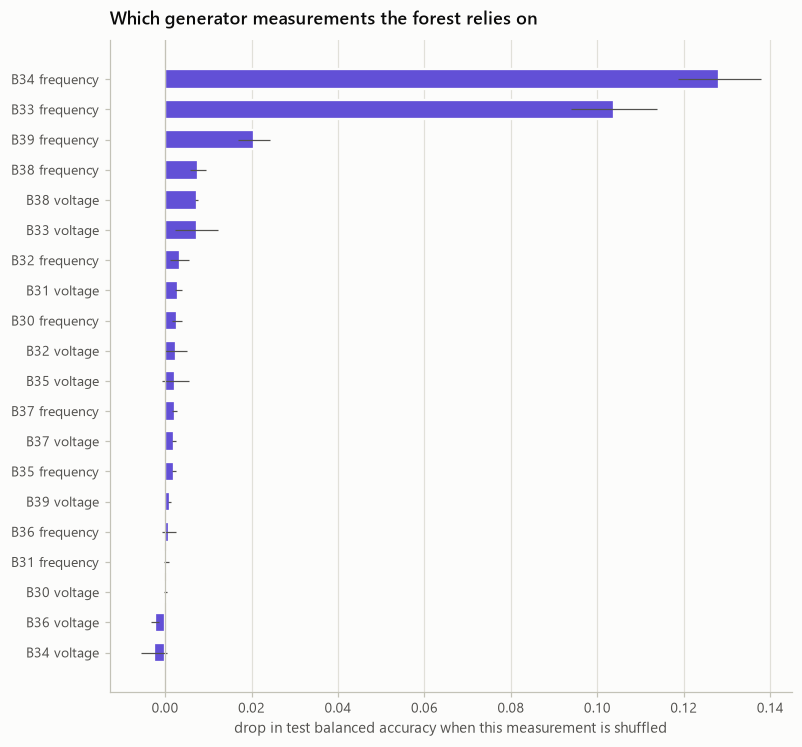

In [24]:
perm = evaluate.grouped_permutation_importance(final, test)
display(perm.head(10))
show(plots.plot_importance(perm), "18_permutation_importance")

,bus,quantity,feature_group,importance,std
0,B34,frequency,B34 frequency,0.3711,0.0
1,B33,frequency,B33 frequency,0.2759,0.0
2,B33,voltage,B33 voltage,0.0609,0.0
3,B39,frequency,B39 frequency,0.0471,0.0
4,B32,frequency,B32 frequency,0.0390,0.0
5,B32,voltage,B32 voltage,0.0370,0.0
6,B35,voltage,B35 voltage,0.0330,0.0
7,B31,voltage,B31 voltage,0.0247,0.0
8,B34,voltage,B34 voltage,0.0210,0.0
9,B31,frequency,B31 frequency,0.0193,0.0


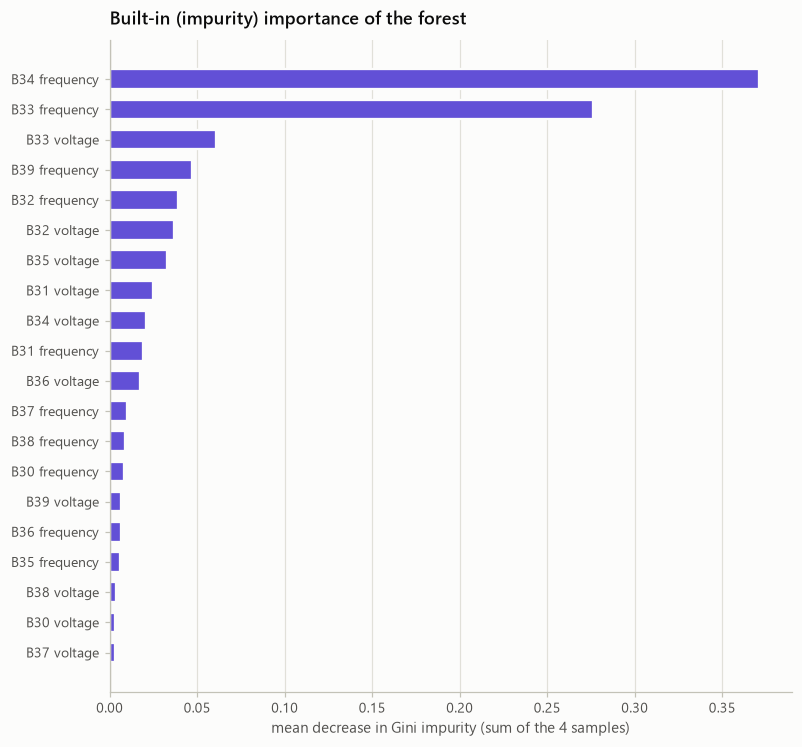

In [25]:
impurity = evaluate.impurity_importance_by_group(final)
display(impurity.head(10))
show(plots.plot_importance(impurity, xlabel="mean decrease in Gini impurity (sum of the 4 samples)",
                           title="Built-in (impurity) importance of the forest"), "19_impurity_importance")

## 8. Save the model and predict new cases

`predict_case(vmag, freq)` takes two 10 x 4 tables - rows B30...B39, columns samples 1-4 - and returns the prediction.
The same is available from the command line: `py predict_rf.py examples/example_case_unstable.csv`.

In [26]:
path = model.save_model(final, best, {"cv": m_cv, "train": m_train, "validation": m_val, "test": m_test}, trainval,
                        notes="First try: all rows kept, outliers not removed. Fitted on train + validation.")
print("Saved model to", path)

Saved model to D:\Aca sem 7\EE4750 - Data Analytics in Power Systems\Claude\Data Anltics - ashen\Data Anltics - ashen\random_forest\models\stability_rf.joblib


In [27]:
from rf_stability.predict import predict_case

case = test.iloc[0]                                   # a test case the final forest has never seen
vmag = [[case[f"{b}_Vmag_{k}"] for k in range(1, 5)] for b in BUSES]
freq = [[case[f"{b}_FreqHz_{k}"] for k in range(1, 5)] for b in BUSES]
print(pd.DataFrame(np.hstack([vmag, freq]), index=BUSES,
                   columns=[f"V{k}" for k in range(1, 5)] + [f"F{k}" for k in range(1, 5)]).round(4))
print("\nactual   :", "Stable" if case[LABEL] == STABLE else "Unstable", f"({case[GROUP]}, {case['Operating_Condition']})")
print("predicted:", predict_case(vmag, freq))

         V1      V2      V3      V4       F1       F2       F3       F4
B30  0.9989  0.9967  0.9954  0.9946  49.9804  49.9279  49.8943  49.8708
B31  0.8065  0.8049  0.8035  0.8021  49.9942  49.9833  49.9770  49.9713
B32  0.9799  0.9786  0.9775  0.9764  49.9948  49.9838  49.9767  49.9699
B33  0.9978  0.9969  0.9959  0.9949  49.9861  49.9742  49.9686  49.9629
B34  1.0066  1.0045  1.0029  1.0015  49.9853  49.9696  49.9662  49.9641
B35  1.0173  1.0159  1.0147  1.0135  49.9948  49.9840  49.9770  49.9704
B36  1.0207  1.0196  1.0186  1.0177  49.9973  49.9879  49.9804  49.9727
B37  1.0158  1.0136  1.0118  1.0104  49.9830  49.9469  49.9244  49.9051
B38  0.8880  0.8860  0.8844  0.8830  49.9856  49.9558  49.9390  49.9261
B39  1.0197  1.0196  1.0195  1.0194  49.9990  49.9967  49.9951  49.9935

actual   : Stable (GenTrip_Bus38, -4%)
predicted: {'prediction': 'Stable', 'p_unstable': 0.173, 'outside_training_range': ['B38_FreqHz_1', 'B38_FreqHz_2', 'B38_FreqHz_3', 'B38_FreqHz_4']}


## 9. Summary

In [28]:
print(f"Settings chosen by grouped 5-fold CV on train : {best}")
print(f"  cross-validated balanced accuracy           : {m_cv['balanced_accuracy']:.3f} +/- {m_cv['std']:.3f}")
for name in ("Validation", "Test"):
    r = results.loc[name]
    print(f"{name:<10} balanced accuracy {r['balanced_accuracy']:.3f} | unstable caught {r['unstable_recall']:.1%} "
          f"| stable correct {r['stable_recall']:.1%} | ROC-AUC {r['roc_auc']:.3f}")

Settings chosen by grouped 5-fold CV on train : {'class_weight': 'balanced', 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 10}
  cross-validated balanced accuracy           : 0.942 +/- 0.041
Validation balanced accuracy 0.969 | unstable caught 96.9% | stable correct 97.0% | ROC-AUC 0.997
Test       balanced accuracy 0.955 | unstable caught 95.9% | stable correct 95.2% | ROC-AUC 0.993


**Reading the numbers.** Validation and test each hold ~106 contingencies, so their scores move by a few points
depending on which contingencies land in them - the cross-validation mean ± spread is the steadier estimate.

**Ideas for the next try**
1. **Handle the impossible readings** - remove or cap them, and compare with this first try on the same split.
2. **More generator-trip cases** - only 10 generator-trip contingencies exist.
3. **Decision threshold** - lowering the 0.5 probability threshold trades false alarms for fewer missed unstable cases.
4. **Extra features** - e.g. the spread of frequency between generators.